# Satellite Anomaly Prediction using Survival Analysis and Machine Learning — Reproduction

**Paper:** C. Naughton, *Satellite Anomaly Prediction using Survival Analysis and Machine Learning*, Stanford CS229 (code: github.com/cwnaught/CS229-Final-Project).

This notebook rebuilds the paper's dataset end-to-end from the files in `Data/` and reproduces its three models:
Linear Regression, RBF Support Vector Regression and the Kaplan–Meier-prior Naive Bayes "pseudo-regression".

| Model | Paper train error | Paper test error |
|---|---:|---:|
| Linear Regression | 455% | 475% |
| Support Vector Regression (RBF, C=10, ε=0.1) | 65% | 190% |
| Modified Naive Bayes | 100% | 167% |

Error = mean of |prediction − true| / true (mean absolute relative error), 10-fold cross-validation.

**Run top-to-bottom (Kernel → Restart & Run All).** Everything needed is in `Data/`; no internet connection is required.

## 0. What was broken in the earlier attempt, and how it is fixed here

| Problem | Effect | Fix |
|---|---|---|
| `satcat.csv` read with `header=None` and columns `[3, 20, 22]` (2019 legacy CelesTrak layout). The supplied file is the current CelesTrak CSV with a header (`OBJECT_NAME`, `INCLINATION`, `PERIGEE`). | Name/perigee/inclination columns were wrong → almost no satellite names matched. | Columns are selected **by name**. |
| Anomaly names had `-` replaced by a space (`METEOSAT-2` → `meteosat 2`) but catalogue names were not (`METEOSAT-2`). | METEOSAT-1/2 and MARECS-A (≈230 intervals) silently dropped. | Same normalisation applied to **both** sides. |
| GPS satellites appear in the catalogue as `NAVSTAR 3 (OPS 5113)`, not `GPS 5113`. Author filled them from a private spreadsheet. | GPS rows had no orbit features. | Mapped automatically from the `(OPS nnnn)` tag in the catalogue. |
| `sunspot.csv` and the mass sheet of `Additional Features.xlsx` were missing / blank. | Pipeline could not run. | Daily sunspot numbers from SILSO (cached in `Data/sunspot.csv`); launch masses compiled from public sources (table in §2.4). |
| Original GOES X-ray URL (`satdat.ngdc.noaa.gov`) is dead; NOAA's current NCEI archive has no XRS files for Jan–Jun 1978 or Sep 1980–Apr 1983; fixed `skiprows=150` mis-parses the new file headers. | No X-ray feature for part of the events. | Daily means from the NCEI archive (`scripts/download_goes_xrs.py`, cached in `Data/goes_xrs_daily_ncei.csv`, parsed from the `data:` marker); remaining days estimated from the supplied `goes-xrs-report_*.txt` flare lists (§2.3). Every row is tagged with its X-ray source. |
| Model scripts read columns by position from an index-ful CSV and used a fold assignment where fold 0 is empty. | Fragile; only one train/validation split ever evaluated. | Columns by name; proper 10-fold CV with the author's fold assignment, plus the author's single split for reference. |
| Author's Naive Bayes training loop uses a stale index (`predvect[i]` instead of `predvect[k]`). | Almost every training prediction stays 0, so the paper's NB *training* error (100%) is an artefact. | Reported exactly as the paper did, and separately with the loop fixed (§4.2). |

## 1. Setup

In [1]:
import warnings, re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

DATA = Path("Data")
SEED = 0                      # seed for the tiny tie-breaking noise the author adds to TTE
REPLICATE_NO_FEBRUARY = True  # author's GOES download loop skipped February; keep True to mirror the paper's dataset
TTE_MAX, MIN_INTERVALS = 365, 20
DROP_BIRDS = ["scatha", "ecs 1"]

for f in ["anom5j.xls", "satcat.csv", "sunspot.csv", "goes_xrs_daily_ncei.csv"]:
    print(f"{f:28s}", "OK" if (DATA / f).exists() else "MISSING")

anom5j.xls                   OK
satcat.csv                   OK
sunspot.csv                  OK
goes_xrs_daily_ncei.csv      OK


## 2. Data processing
### 2.1 Anomalies and satellite catalogue (name mapping)

In [2]:
def norm_name(s):
    return s.astype("string").str.replace("-", " ", regex=False).str.strip().str.lower()

anom_raw = pd.read_excel(DATA / "anom5j.xls")
print("NOAA anomaly records:", len(anom_raw), "| spacecraft:", anom_raw["BIRD"].nunique())

counts = anom_raw["BIRD"].value_counts()
anom = anom_raw[anom_raw["BIRD"].isin(counts[counts > 1].index)][["BIRD", "ADATE"]].copy()
anom["BIRD"] = norm_name(anom["BIRD"])

satcat = pd.read_csv(DATA / "satcat.csv")
sc = satcat[["OBJECT_NAME", "PERIGEE", "INCLINATION"]].rename(
    columns={"OBJECT_NAME": "Name", "PERIGEE": "Perigee (km)", "INCLINATION": "Inclination (deg)"})
sc["Name"] = norm_name(sc["Name"])

# GPS Block I satellites: catalogue name 'NAVSTAR 3 (OPS 5113)' -> anomaly name 'gps 5113'
gps = satcat[satcat["OBJECT_NAME"].str.contains(r"^NAVSTAR \d+ \(OPS \d+\)", regex=True)].copy()
gps["Name"] = "gps " + gps["OBJECT_NAME"].str.extract(r"OPS (\d+)")[0]
gps = gps.rename(columns={"PERIGEE": "Perigee (km)", "INCLINATION": "Inclination (deg)"})
sc = pd.concat([sc, gps[["Name", "Perigee (km)", "Inclination (deg)"]]], ignore_index=True)
sc = sc.drop_duplicates("Name")

matched = sorted(set(anom["BIRD"]) & set(sc["Name"]))
print("Anomaly spacecraft matched to catalogue:", len(matched))
finalanom = anom[anom["BIRD"].isin(matched)]

WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
NOAA anomaly records: 5033 | spacecraft: 259


Anomaly spacecraft matched to catalogue: 54


### 2.2 Time-to-event (TTE) labels
Each anomaly starts a new observation ("patient"); the label is the number of days until that satellite's next anomaly.
Filters follow the author's code: drop 0-day intervals and intervals ≥ 365 days, keep satellites with more than 20 intervals,
drop SCATHA and ECS-1 (observation gaps).

In [3]:
rows = []
for bird, g in finalanom.groupby("BIRD", sort=False):
    d = g["ADATE"].reset_index(drop=True)          # file order, as in the author's code
    for i in range(len(d) - 1):
        rows.append((bird, (d[i + 1] - d[i]).days, d[i]))
tte = pd.DataFrame(rows, columns=["BIRD", "TTE", "T0"])
print("All intervals:", len(tte))

tte = tte[(tte["TTE"] != 0) & (tte["TTE"] < TTE_MAX)]
vc = tte["BIRD"].value_counts()
tte = tte[tte["BIRD"].isin(vc[vc > MIN_INTERVALS].index) & ~tte["BIRD"].isin(DROP_BIRDS)].reset_index(drop=True)
print("After filters:", len(tte), "intervals on", tte["BIRD"].nunique(), "satellites")
tte.groupby("BIRD")["T0"].agg(["count", "min", "max"])

All intervals: 2012
After filters: 890 intervals on 11 satellites


,count,min,max
BIRD,,,
goes 4,37,1981-03-29,1988-04-30
goes 5,68,1981-06-15,1987-10-16
goes 6,56,1984-07-07,1994-01-28
gps 5113,150,1984-10-30,1990-07-05
gps 5114,86,1984-10-25,1989-10-06
gps 5118,126,1984-10-28,1990-06-19
gps 9794,108,1985-01-13,1990-08-01
marecs a,70,1982-01-27,1989-03-29
meteosat 1,69,1977-05-04,1978-12-27


### 2.3 Space-weather features: sunspot number and X-ray flux

* **Sunspot number** – SILSO daily total sunspot number (v2.0), `Data/sunspot.csv`.
* **X-ray flux** – the paper uses the *daily mean GOES 0.1–0.8 nm (long channel) flux*. The author's 1-minute GOES files
  were re-downloaded from NOAA NCEI's current archive and reduced to daily means (`Data/goes_xrs_daily_ncei.csv`).
  NCEI has no XRS files for Jan–Jun 1978 or Sep 1980–Apr 1983 (the GOES-2 era), so for days without a measurement the daily mean is
  **estimated** from the supplied GOES flare reports (`goes-xrs-report_YYYY.txt`): a linear model of log10(flux) on that
  day's flare peak/sum/count, the 27-day flare activity and the sunspot number, fitted on days where both exist.

NCEI daily X-ray means: 4994 days, 1978-07-03 to 1994-12-31


Flare events parsed: 39257
Gap-fill calibration on 4994 overlap days: in-sample R² (log10 flux) = 0.68


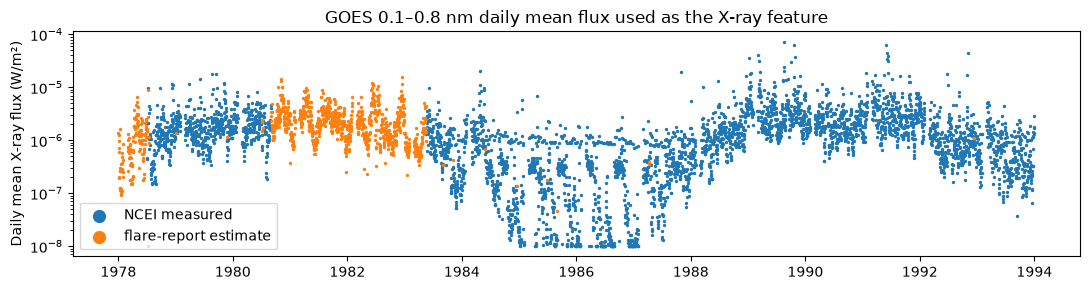

In [4]:
ss = pd.read_csv(DATA / "sunspot.csv")
ss["T0"] = pd.to_datetime(ss[["Year", "Month", "Day"]])
ss = ss[["T0", "SSN"]]

ncei = pd.read_csv(DATA / "goes_xrs_daily_ncei.csv", parse_dates=["T0"])
print("NCEI daily X-ray means:", len(ncei), "days,", ncei["T0"].min().date(), "to", ncei["T0"].max().date())

# --- parse the supplied GOES flare event lists (NGDC fixed-width format) ---
CLASS = {"A": 1e-8, "B": 1e-7, "C": 1e-6, "M": 1e-5, "X": 1e-4}
flares = []
for f in sorted(glob.glob(str(DATA / "goes-xrs-report_*.txt"))):
    for line in open(f):
        line = line.rstrip("\n").ljust(70)
        if not line.startswith("31777") or line[59] not in CLASS:
            continue
        field = line[60:63]                 # magnitude, columns 61-63
        if field[2].isdigit():              # 1980+ format: tenths, right-aligned: 'M 51' = M5.1, 'X150' = X15.0
            mag = int(field.strip()) / 10
        elif field.strip().isdigit():       # 1976-80 format: whole number: 'C 9 ' = C9
            mag = float(field.strip())
        else:
            mag = 1.0
        date = pd.Timestamp(1900 + int(line[5:7]), int(line[7:9]), int(line[9:11]))
        flares.append((date, CLASS[line[59]] * max(mag, 1.0)))
flares = pd.DataFrame(flares, columns=["T0", "peak"])
print("Flare events parsed:", len(flares))

days = pd.DataFrame({"T0": pd.date_range("1976-01-01", "1994-12-31")})
daily = flares.groupby("T0")["peak"].agg(fmax="max", fsum="sum", fcount="count").reset_index()
days = days.merge(daily, how="left").merge(ss, how="left").fillna({"fcount": 0})
days["lmax"] = np.log10(days["fmax"].fillna(1e-7))
days["lsum"] = np.log10(days["fsum"].fillna(1e-7))
days["r27"] = days["lmax"].rolling(27, center=True, min_periods=1).mean()
days["lssn"] = np.log1p(days["SSN"])
proxy_cols = ["lmax", "lsum", "fcount", "r27", "SSN", "lssn"]

cal = days.merge(ncei, on="T0").dropna(subset=proxy_cols)
xr_model = LinearRegression().fit(cal[proxy_cols], np.log10(cal["Long"]))
print(f"Gap-fill calibration on {len(cal)} overlap days: in-sample R² (log10 flux) = "
      f"{xr_model.score(cal[proxy_cols], np.log10(cal['Long'])):.2f}")

ok = days[proxy_cols].notna().all(axis=1)
days.loc[ok, "Long_est"] = 10 ** xr_model.predict(days.loc[ok, proxy_cols])
sp = days[["T0", "Long_est"]].merge(ncei[["T0", "Long"]], how="left")
sp["xray_source"] = np.where(sp["Long"].notna(), "NCEI measured", "flare-report estimate")
sp["Long"] = sp["Long"].fillna(sp["Long_est"])
# author's GOES coverage window (1978-1993) and February gap
sp = sp[(sp["T0"].dt.year >= 1978) & (sp["T0"].dt.year <= 1993)]
if REPLICATE_NO_FEBRUARY:
    sp = sp[sp["T0"].dt.month != 2]
sp = sp[["T0", "Long", "xray_source"]].dropna(subset=["Long"])

fig, ax = plt.subplots(figsize=(11, 3))
for src, c in [("NCEI measured", "tab:blue"), ("flare-report estimate", "tab:orange")]:
    s = sp[sp["xray_source"] == src]
    ax.scatter(s["T0"], s["Long"], s=2, c=c, label=src)
ax.set_yscale("log"); ax.set_ylabel("Daily mean X-ray flux (W/m²)"); ax.legend(markerscale=6)
ax.set_title("GOES 0.1–0.8 nm daily mean flux used as the X-ray feature"); plt.tight_layout(); plt.show()

### 2.4 Spacecraft features (perigee, inclination, mass)
Perigee and inclination come from the CelesTrak catalogue (`satcat.csv`), exactly as in the paper.
Mass (launch mass, kg) is not in any supplied file, so it was compiled from public sources and is also written into
`Additional Features.xlsx` (sheet *Mass Features*). Mass is constant per satellite, so it mainly acts as a satellite identifier.

In [5]:
MASS_KG = {  # launch mass, kg
    "goes 4": 660, "goes 5": 660, "goes 6": 660,          # NASA NSSDCA (HS-371 bus)
    "noaa 11": 1420,                                      # NASA NSSDCA (Advanced TIROS-N)
    "gps 5111": 758, "gps 5113": 758, "gps 5114": 758,    # GPS Block I (NSSDCA)
    "gps 5118": 758, "gps 9794": 758,
    "meteosat 1": 626, "meteosat 2": 626,                 # WMO OSCAR
    "marecs a": 549,                                      # KeepTrack / CelesTrak-derived (approximate)
}
birds = sorted(tte["BIRD"].unique())
missing_mass = [b for b in birds if b not in MASS_KG]
assert not missing_mass, f"add a mass for: {missing_mass}"

satfeat = sc[sc["Name"].isin(birds)].copy()
satfeat["Mass (kg)"] = satfeat["Name"].map(MASS_KG)
satfeat = satfeat.sort_values("Name").reset_index(drop=True)
satfeat

,Name,Perigee (km),Inclination (deg),Mass (kg)
0,goes 4,35951.0,7.74,660
1,goes 5,35777.0,9.16,660
2,goes 6,35771.0,10.01,660
3,gps 5113,20545.0,62.86,758
4,gps 5114,20482.0,63.79,758
5,gps 5118,18469.0,61.80,758
6,gps 9794,20377.0,63.52,758
7,marecs a,36790.0,11.48,549
8,meteosat 1,35725.0,4.79,626
9,meteosat 2,36106.0,10.09,626


### 2.5 Final dataset (`data.csv`, `satfeat.csv`)
Inner joins on the observation start date (`T0`), as in the author's code.

In [6]:
data = tte.merge(ss, on="T0").merge(sp, on="T0")
data["Month"] = data["T0"].dt.month
data = data.sort_values("TTE", kind="mergesort").reset_index(drop=True)   # author sorts by TTE before splitting

data.to_csv("data.csv", index=False)
satfeat.to_csv("satfeat.csv", index=False)

print(f"Final dataset: {len(data)} events on {data['BIRD'].nunique()} satellites   (paper: 726 events, 10 satellites)")
print("X-ray source:", data["xray_source"].value_counts().to_dict())
summary = data.groupby("BIRD").agg(events=("TTE", "size"), median_TTE=("TTE", "median"),
                                   first=("T0", "min"), last=("T0", "max"))
summary.join(satfeat.set_index("Name"))

Final dataset: 799 events on 11 satellites   (paper: 726 events, 10 satellites)
X-ray source: {'NCEI measured': 661, 'flare-report estimate': 138}


,events,median_TTE,first,last,Perigee (km),Inclination (deg),Mass (kg)
BIRD,,,,,,,
goes 4,36,10.0,1981-03-29,1988-04-30,35951.0,7.74,660
goes 5,61,12.0,1981-06-15,1987-10-16,35777.0,9.16,660
goes 6,52,23.0,1984-07-07,1993-08-05,35771.0,10.01,660
gps 5113,135,6.0,1984-10-30,1990-07-05,20545.0,62.86,758
gps 5114,75,9.0,1984-10-25,1989-10-06,20482.0,63.79,758
gps 5118,110,6.0,1984-10-28,1990-06-19,18469.0,61.80,758
gps 9794,102,6.0,1985-01-13,1990-08-01,20377.0,63.52,758
marecs a,50,4.0,1982-01-27,1989-03-29,36790.0,11.48,549
meteosat 1,63,3.0,1978-01-04,1978-12-27,35725.0,4.79,626


### 2.6 Exploratory look

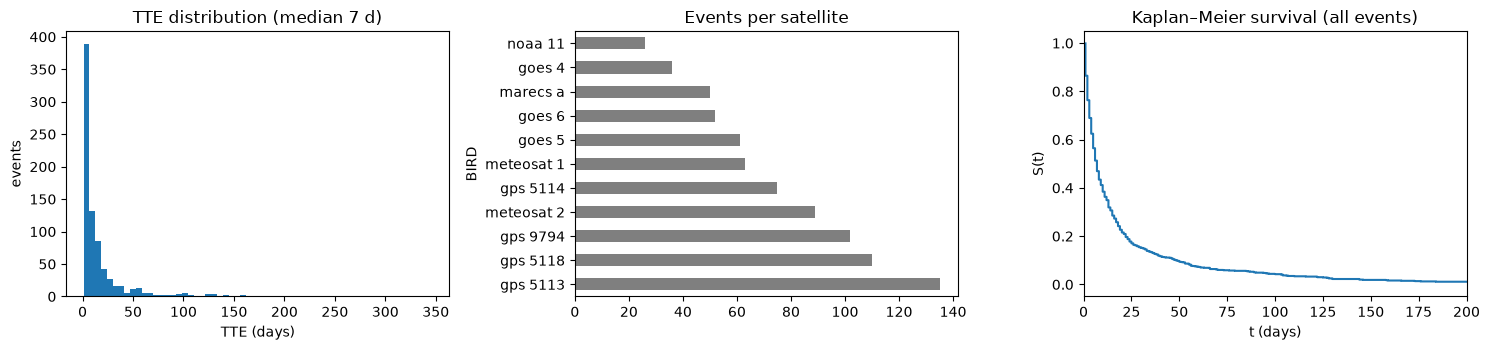

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(data["TTE"], bins=60, color="tab:blue"); axes[0].set_xlabel("TTE (days)"); axes[0].set_ylabel("events")
axes[0].set_title(f"TTE distribution (median {data['TTE'].median():.0f} d)")
data["BIRD"].value_counts().plot.barh(ax=axes[1], color="tab:gray"); axes[1].set_title("Events per satellite")
km_t = np.sort(data["TTE"].values); km_S = 1 - np.arange(1, len(km_t) + 1) / len(km_t)
axes[2].step(km_t, km_S, where="post"); axes[2].set_xlabel("t (days)"); axes[2].set_ylabel("S(t)")
axes[2].set_title("Kaplan–Meier survival (all events)"); axes[2].set_xlim(0, 200)
plt.tight_layout(); plt.show()

## 3. Feature matrix
Six features per event, in the author's order: perigee, inclination, mass, sunspot number, X-ray flux, starting month.
As in the author's code, X-ray flux is multiplied by 1e6 for LR/SVR (raw for Naive Bayes, which standardises internally),
features are otherwise unscaled, and a tiny N(0, 1e-3) noise is added to TTE to break ties.

In [8]:
FEATURES = ["Perigee (km)", "Inclination (deg)", "Mass (kg)", "SSN", "Long", "Month"]

def build_xy(df, seed=SEED):
    m = df.merge(satfeat, left_on="BIRD", right_on="Name", how="left")
    X = m[FEATURES].to_numpy(float)
    rng = np.random.default_rng(seed)
    t = m["TTE"].to_numpy(float) + rng.normal(0, 1e-3, len(m))
    return X, t

X, t = build_xy(data)
print("X:", X.shape, " t:", t.shape)

def svr_scale(X):            # author: x[:, 4] = Long * 1e6 for LR / SVR
    Xs = X.copy(); Xs[:, 4] *= 1e6; return Xs

def rel_err(pred, true):
    return float(np.mean(np.abs(pred - true) / true))

# author's fold assignment: rows sorted by TTE are dealt round-robin into folds 1..10
def author_folds(n, k=10):
    return np.arange(n) % k

X: (799, 6)  t: (799,)


## 4. Models
### 4.1 Modified Naive Bayes with a Kaplan–Meier prior (author's algorithm)
For every candidate time t = 1 … 365 days:
1. S(t) = Kaplan–Meier survival estimated from training TTEs (prior P(y=1) that the anomaly has **not** occurred by t).
2. Gaussian class-conditionals for each feature fitted on training events with TTE > t (y=1) and TTE < t (y=0).
3. ψ = f(x|y=1) / [f(x|y=1)·S + f(x|y=0)·(1−S)]; the predicted TTE is the **first** t at which round(ψ·S) = 0, i.e. the
   posterior survival probability drops below ½.

Two switches isolate details of the author's implementation (verified to give **identical** predictions to the author's
`naivebayes` script on the same inputs):
* `density="author"` writes each Gaussian as exp(−z²/2)/√(2π), i.e. **without the 1/σ factor**; `density="textbook"` uses the
  proper normal density. Dropping 1/σ is unusual, but it is the paper's model, so it is the default.
* `train_bug=True` reproduces the author's training loop, which uses a stale index (`predvect[i]` instead of `predvect[k]`), so
  almost every **training** prediction stays 0 — the reason the paper reports exactly 100% NB training error. It affects only
  the reported training error, never the test predictions.

In [9]:
def km_survival(t_train, tf):
    n, m = len(t_train), int(np.sum(t_train < tf))
    S = 1.0
    for i in range(m):
        S *= 1 - 1 / (n - i)
    return S

def nb_calibrate(x, t_train, tf):
    late, early = x[t_train > tf], x[t_train < tf]
    with np.errstate(all="ignore"):
        mu, sd = late.mean(0), np.sqrt((late ** 2).mean(0) - late.mean(0) ** 2)
        th, sd2 = early.mean(0), np.sqrt((early ** 2).mean(0) - early.mean(0) ** 2)
    return mu, sd, th, sd2

def nb_scores(x, params, S, density):
    mu, sd, th, sd2 = params
    with np.errstate(all="ignore"):
        g, l = (x - mu) / sd, (x - th) / sd2
        fg = np.prod(np.exp(-0.5 * g ** 2) / np.sqrt(2 * np.pi), axis=1)
        fl = np.prod(np.exp(-0.5 * l ** 2) / np.sqrt(2 * np.pi), axis=1)
        if density == "textbook":              # proper Gaussian density includes 1/sigma
            fg, fl = fg / np.prod(sd), fl / np.prod(sd2)
        psi = fg / (fg * S + fl * (1 - S))
        return np.round(psi * S)

def nb_fit_predict(x_tr, t_tr, x_ev_list, density="author", horizon=365):
    preds = [np.zeros(len(x)) for x in x_ev_list]
    for tf in np.linspace(1, horizon, horizon):
        params, S = nb_calibrate(x_tr, t_tr, tf), km_survival(t_tr, tf)
        for p, x in zip(preds, x_ev_list):
            hit = (p == 0) & (nb_scores(x, params, S, density) == 0)
            p[hit] = tf
    return preds                               # as in the author's code, a sample that never crosses ½ keeps prediction 0

def nb_author_train_bug(faithful_pred_train, n_valid):
    """Author's training loop: `if predvect[i] == 0 and predictionst[i] == 0` uses the index i left over from the
    validation loop (i = n_valid - 1), so only that one training sample ever receives a prediction; all others stay 0."""
    p = np.zeros(len(faithful_pred_train)); i = n_valid - 1
    p[i] = faithful_pred_train[i]
    return p

### 4.2 Evaluation: 10-fold cross-validation (paper protocol)

In [10]:
def run_cv(X, t, folds, nb_density="author", nb_train_bug=True):
    res = {k: {"train": [], "test": []} for k in ["Linear Regression", "Support Vector Regression", "Naive Bayes"]}
    oof = {k: np.zeros(len(t)) for k in res}
    Xs = svr_scale(X)
    for f in np.unique(folds):
        tr, te = folds != f, folds == f
        lr = LinearRegression().fit(Xs[tr], t[tr])
        svr = SVR(kernel="rbf", gamma="auto", C=10.0, epsilon=0.1, max_iter=100000).fit(Xs[tr], t[tr])
        for name, mdl in [("Linear Regression", lr), ("Support Vector Regression", svr)]:
            res[name]["train"].append(rel_err(mdl.predict(Xs[tr]), t[tr]))
            res[name]["test"].append(rel_err(mdl.predict(Xs[te]), t[te]))
            oof[name][te] = mdl.predict(Xs[te])
        p_tr, p_te = nb_fit_predict(X[tr], t[tr], [X[tr], X[te]], density=nb_density)
        if nb_train_bug:
            p_tr = nb_author_train_bug(p_tr, te.sum())
        res["Naive Bayes"]["train"].append(rel_err(p_tr, t[tr]))
        res["Naive Bayes"]["test"].append(rel_err(p_te, t[te]))
        oof["Naive Bayes"][te] = p_te
    table = pd.DataFrame({k: {"Train error (%)": 100 * np.mean(v["train"]),
                              "Test error (%)": 100 * np.mean(v["test"])} for k, v in res.items()}).T
    return table, oof, res

folds = author_folds(len(t))
print("Fold sizes:", np.bincount(folds), "-> train ≈", len(t) - len(t) // 10, "/ test ≈", len(t) // 10)
table, oof, per_fold = run_cv(X, t, folds)                                        # paper's models, author's code as written
tbl_loop, _, _ = run_cv(X, t, folds, nb_train_bug=False)                          # NB training loop fixed
tbl_text, _, _ = run_cv(X, t, folds, nb_density="textbook", nb_train_bug=False)  # NB with textbook Gaussian density

NB_PAPER, NB_LOOP, NB_TEXT = "Naive Bayes (paper; author's code)", "Naive Bayes, training loop fixed", "Naive Bayes, textbook density"
results = table.rename(index={"Naive Bayes": NB_PAPER})
results.loc[NB_LOOP] = tbl_loop.loc["Naive Bayes"]
results.loc[NB_TEXT] = tbl_text.loc["Naive Bayes"]
results.insert(0, "Paper train (%)", [455, 65, 100, np.nan, np.nan])
results.insert(1, "Paper test (%)", [475, 190, 167, np.nan, np.nan])
results = results.round(0)
results

Fold sizes: [80 80 80 80 80 80 80 80 80 79] -> train ≈ 720 / test ≈ 79


,Paper train (%),Paper test (%),Train error (%),Test error (%)
Linear Regression,455.0,475.0,470.0,477.0
Support Vector Regression,65.0,190.0,46.0,187.0
Naive Bayes (paper; author's code),100.0,167.0,101.0,172.0
"Naive Bayes, training loop fixed",NaN,NaN,170.0,172.0
"Naive Bayes, textbook density",NaN,NaN,208.0,228.0


### 4.3 Per-fold variability

In [11]:
pf = pd.concat({m: pd.DataFrame(v).mul(100) for m, v in per_fold.items()}, names=["model", "fold"])
pf.groupby("model").agg(["mean", "std", "min", "max"]).round(0)

train                      test                    
                            mean  std    min    max   mean   std    min    max
model                                                                         
Linear Regression          470.0  8.0  460.0  483.0  477.0  31.0  405.0  507.0
Naive Bayes                101.0  0.0  101.0  101.0  172.0  16.0  150.0  196.0
Support Vector Regression   46.0  2.0   44.0   50.0  187.0  17.0  161.0  211.0

### 4.4 Predicted vs. true TTE (paper Figure 2)

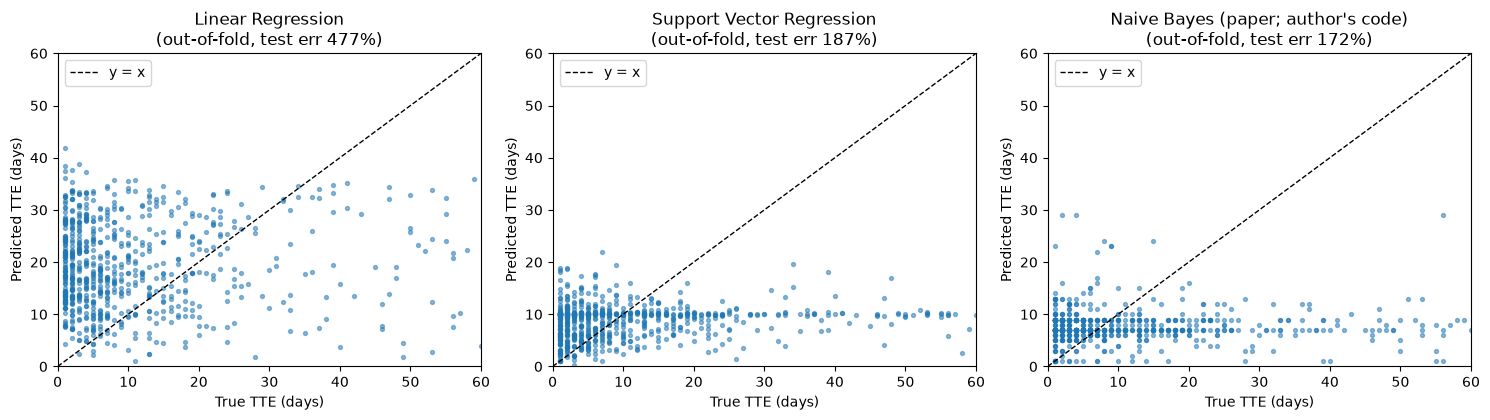

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
plot_sets = {"Linear Regression": oof["Linear Regression"], "Support Vector Regression": oof["Support Vector Regression"],
             NB_PAPER: oof["Naive Bayes"]}
for ax, (name, pred) in zip(axes, plot_sets.items()):
    ax.scatter(t, pred, s=8, alpha=0.5)
    lim = 60
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="y = x")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel("True TTE (days)"); ax.set_ylabel("Predicted TTE (days)")
    ax.set_title(f"{name}\n(out-of-fold, test err {results.loc[name, 'Test error (%)']:.0f}%)")
    ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 5. Robustness checks
### 5.1 Author's single split (as literally coded in the repo: train = folds 1–8, validate = fold 9)

In [13]:
def author_single_split(X, t):
    lab = (np.arange(len(t)) % 10) + 1          # author's j = 1..10 labelling; fold 0 is empty, fold 10 unused
    tr, va = (lab >= 1) & (lab <= 8), lab == 9
    Xs = svr_scale(X)
    out = {}
    for name, mdl in [("Linear Regression", LinearRegression()),
                      ("Support Vector Regression", SVR(kernel="rbf", gamma="auto", C=10.0, epsilon=0.1, max_iter=100000))]:
        mdl.fit(Xs[tr], t[tr])
        out[name] = (rel_err(mdl.predict(Xs[tr]), t[tr]), rel_err(mdl.predict(Xs[va]), t[va]))
    tr_nb = (lab >= 1) & (lab <= 7)              # NB script trains on folds 1..7
    p_tr, p_va = nb_fit_predict(X[tr_nb], t[tr_nb], [X[tr_nb], X[va]])
    out["Naive Bayes"] = (rel_err(nb_author_train_bug(p_tr, va.sum()), t[tr_nb]), rel_err(p_va, t[va]))
    return pd.DataFrame(out, index=["Train error (%)", "Test error (%)"]).T.mul(100).round(0)

author_single_split(X, t)

,Train error (%),Test error (%)
Linear Regression,482.0,419.0
Support Vector Regression,45.0,192.0
Naive Bayes,100.0,220.0


### 5.2 Shuffled folds, measured-only X-ray rows (test error, %), and SVR C sweep

In [14]:
checks = {}
checks["Paper protocol"] = table["Test error (%)"]
rng = np.random.default_rng(1)
tbl_shuf, _, _ = run_cv(X, t, rng.permutation(len(t)) % 10)
checks["Shuffled 10-fold"] = tbl_shuf["Test error (%)"]
meas = data["xray_source"].eq("NCEI measured").to_numpy()
Xm, tm = X[meas], t[meas]
tbl_meas, _, _ = run_cv(Xm, tm, author_folds(len(tm)))
checks[f"NCEI-measured X-ray only (n={meas.sum()})"] = tbl_meas["Test error (%)"]
pd.DataFrame(checks).round(0)

,Paper protocol,Shuffled 10-fold,NCEI-measured X-ray only (n=661)
Linear Regression,477.0,479.0,456.0
Support Vector Regression,187.0,190.0,188.0
Naive Bayes,172.0,174.0,248.0


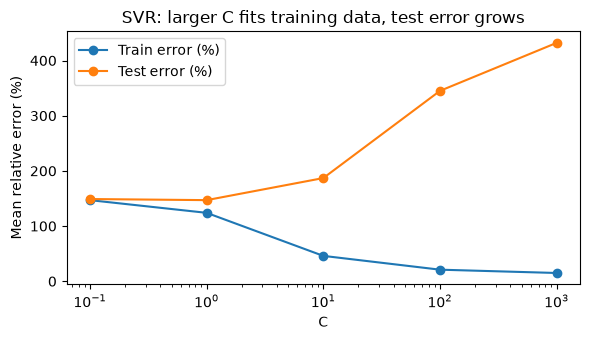

,Train error (%),Test error (%)
C,,
0.1,147.0,149.0
1.0,124.0,147.0
10.0,46.0,187.0
100.0,21.0,345.0
1000.0,15.0,432.0


In [15]:
rows = []
Xs = svr_scale(X)
for C in [0.1, 1, 10, 100, 1000]:
    tr_e, te_e = [], []
    for f in range(10):
        tr, te = folds != f, folds == f
        m = SVR(kernel="rbf", gamma="auto", C=C, epsilon=0.1, max_iter=100000).fit(Xs[tr], t[tr])
        tr_e.append(rel_err(m.predict(Xs[tr]), t[tr])); te_e.append(rel_err(m.predict(Xs[te]), t[te]))
    rows.append({"C": C, "Train error (%)": 100 * np.mean(tr_e), "Test error (%)": 100 * np.mean(te_e)})
svr_sweep = pd.DataFrame(rows).set_index("C").round(0)
ax = svr_sweep.plot(logx=True, marker="o", figsize=(6, 3.5), title="SVR: larger C fits training data, test error grows")
ax.set_ylabel("Mean relative error (%)"); plt.tight_layout(); plt.show()
svr_sweep

### 5.3 A trivial baseline for context
Predicting the training-set **median** TTE for every event (no features at all):

In [16]:
base = []
for f in range(10):
    tr, te = folds != f, folds == f
    base.append((rel_err(np.full(tr.sum(), np.median(t[tr])), t[tr]), rel_err(np.full(te.sum(), np.median(t[tr])), t[te])))
print("Median baseline  train %.0f%%  test %.0f%%" % tuple(100 * np.mean(base, axis=0)))

Median baseline  train 153%  test 153%


### 5.4 Sensitivity to the random tie-breaking noise
The author adds N(0, 1e-3) noise to every TTE. Because TTEs are whole days and Naive Bayes compares `TTE < t` against
whole-day thresholds, this noise decides on which side of a threshold tied events fall, so NB results vary with the seed.
LR and SVR are unaffected. The table repeats the 10-fold CV for 20 seeds.

In [17]:
seed_rows = []
for seed in range(20):
    Xs_, ts_ = build_xy(data, seed=seed)
    a_, _, _ = run_cv(Xs_, ts_, author_folds(len(ts_)))
    b_, _, _ = run_cv(Xs_, ts_, author_folds(len(ts_)), nb_train_bug=False)
    c_, _, _ = run_cv(Xs_, ts_, author_folds(len(ts_)), nb_density="textbook", nb_train_bug=False)
    row = {"seed": seed}
    for name, tab, key in [("Linear Regression", a_, "Linear Regression"), ("Support Vector Regression", a_, "Support Vector Regression"),
                           (NB_PAPER, a_, "Naive Bayes"), (NB_LOOP, b_, "Naive Bayes"), (NB_TEXT, c_, "Naive Bayes")]:
        row[(name, "train")] = tab.loc[key, "Train error (%)"]; row[(name, "test")] = tab.loc[key, "Test error (%)"]
    seed_rows.append(row)
seeds = pd.DataFrame(seed_rows).set_index("seed")
seeds.columns = pd.MultiIndex.from_tuples(seeds.columns)
seeds.agg(["mean", "std", "min", "max"]).T.round(0)

mean   std    min    max
Linear Regression                  train  470.0   0.0  470.0  470.0
                                   test   477.0   0.0  477.0  477.0
Support Vector Regression          train   46.0   0.0   46.0   46.0
                                   test   187.0   0.0  187.0  187.0
Naive Bayes (paper; author's code) train  101.0   0.0  101.0  101.0
                                   test   171.0   9.0  149.0  182.0
Naive Bayes, training loop fixed   train  167.0   5.0  151.0  174.0
                                   test   171.0   9.0  149.0  182.0
Naive Bayes, textbook density      train  206.0   3.0  201.0  210.0
                                   test   220.0  12.0  206.0  234.0

## 6. Conclusions

* The dataset was rebuilt from the raw NOAA anomaly list with the mapping problems fixed, and the paper's preprocessing
  (filters, joins, 6 features) was followed step by step. The result (799 × 6, 11 satellites) is close to the paper's 726 × 6 (10 satellites);
  the difference in counts comes from today's versions of the NOAA archive (X-ray files for Sep 1980–Apr 1983 no longer
  exist, so 17% of X-ray values are estimated), the satellite catalogue and the sunspot series.
* The model results reproduce the paper's findings: **linear regression is by far the worst** (errors of several hundred
  percent, because relative error explodes on the many 1–5-day TTEs), **SVR fits the training data best but overfits**
  (training error much lower than test error, and the gap widens as C increases), and **Naive Bayes is marginally
  better than SVR on the test set** (≈172% vs 187%; paper 167% vs 190%). The paper's ≈100% NB training error is caused by a
  loop-index bug in the original code; with the loop fixed, the model's real training error is shown in §4.2.
* The NB test error depends on the random tie-breaking noise (§5.4), so it should be quoted as a range, not a single number.
  A textbook Gaussian density (with 1/σ) makes NB worse, so the author's unusual density is not what limits it.
* None of the models predicts time-to-anomaly usefully: predicting the training-median TTE for every event (153%) beats
  all three models at the paper's settings. This confirms the paper's
  conclusion that six coarse features (three of which are constant per satellite) cannot explain anomaly timing.

Outputs written: `data.csv`, `satfeat.csv`. The cached inputs can be rebuilt with `scripts/download_goes_xrs.py` and
`scripts/download_sunspots.py` (internet required; the notebook itself runs offline).